# Final pipeline: fine-tuned text encoder + NAGphormer + LLM fusion + graph label-shift correction

CS5284 Group 4. Node classification of 54,025 Amazon products into 47 categories (TAPE's ogbn-products subset) on
the official sales-rank split: train = best-sellers, test = the long tail. The split causes a large **label shift**
(train vs test label distribution: total variation 0.245), which is what the pipeline is built around.

| Step | What | Where |
|---|---|---|
| 1 | Fine-tune `gte-large-en-v1.5` on the train nodes; its [CLS] vector is the node feature | `scripts/finetune_lm.py` |
| 2 | NAGphormer (hop tokens X, ÂX, ..., Â⁶X read by a Transformer) on the co-purchase graph | `scripts/export_probs.py` |
| 3 | Bayesian fusion with GPT-3.5's zero-shot answer through its confusion matrix (weight 1) | `scripts/run_final.py` |
| 4 | PPR local prior: label-shift correction with a node-specific prior diffused over the graph (λ = 1) | `src/label_shift.py` |
| 5 | One round of belief propagation over co-purchase, text-kNN and sibling (2-hop) edges | `src/label_shift.py` |

Everything that is tuned is chosen on **val** (temperature, LLM combination, PPR setting, BP weights). The LLM weight
and λ are not tuned: both are fixed at 1 by Bayes' rule (the README explains how test results informed this).
Otherwise test labels are only read to report. *Cold start* removes every co-purchase edge touching a test node at inference.
The full method, ablations and negative results are in `docs/method.md` and `docs/research_log.md`.

**Runtime.** With `TRAIN = False` the notebook downloads the checkpoints and embeddings (a 3.4 GB zip) and runs on a
CPU in about 30 minutes, most of it the post-hoc grid in step 3. With `TRAIN = True` it retrains the GNNs (a GPU, a
few minutes per seed); re-fine-tuning the encoder is `scripts/finetune_lm.py --save-ckpt` (about 20 min per seed).

In [1]:
import hashlib, json, os, subprocess, sys, urllib.request
from pathlib import Path

REPO = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "requirements.txt").is_file() and (p / "src").is_dir())  # works from anywhere in the repo
sys.path.insert(0, str(REPO))
os.chdir(REPO)

TRAIN = False          # True: retrain the GNNs instead of loading their checkpoints
DEVICE = "cuda:0"      # used only when TRAIN is True or for the encoder demo
ENC_SEEDS = [0, 1, 2]  # encoder fine-tuning seeds; each has 3 GNN seeds
PY = sys.executable
print(REPO)

<repo>


## 0. Data and artefacts

The graph, text and GPT-3.5 answers come from TAPE (pinned commit, SHA-256 checked). The checkpoints, embeddings and our Qwen answers are in a public Google Drive zip, downloaded and unpacked into `outputs/` by `scripts/download_artifacts.py` (no login needed).

In [2]:
def fetch(url, path, sha256):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == sha256, f"{path} does not match its manifest"

for item in json.loads((REPO / "data/TAPE/download_manifest.json").read_text()):
    fetch(item["url"], REPO / "data/TAPE" / Path(item["url"]).name, item["sha256"])
gpt = json.loads((REPO / "results/shared/tape_gpt_preds_manifest.json").read_text())
fetch(gpt["source"], REPO / gpt["file"], gpt["sha256"])

if not (REPO / "outputs/embeddings/ft-gte-large-r_s0.npy").exists():
    subprocess.run([PY, "scripts/download_artifacts.py"], check=True)
print("data and artefacts ready")

data and artefacts ready


## 1. The fine-tuned encoder

The checkpoint is a `gte-large-en-v1.5` encoder plus the linear head it was fine-tuned with. On its own (text only, no graph, no LLM) it already classifies; the GNN uses its [CLS] vectors. This cell needs the encoder checkpoint (included in the zip above) and is skipped otherwise.

In [3]:
import numpy as np, pandas as pd, torch
from src.data import load_products
from src.text_clean import build_original_text

graph, text = load_products()
names = pd.read_csv(REPO / "data/TAPE/labelidx2productcategory.csv.gz")["product category"].tolist()
y = graph.y.numpy()
tr, va, te = graph.train_mask.numpy(), graph.val_mask.numpy(), graph.test_mask.numpy()
print(f"{graph.num_nodes} nodes, {graph.edge_index.size(1) // 2} undirected co-purchase edges, "
      f"train {tr.sum()} / val {va.sum()} / test {te.sum()}")

ckpt = REPO / "outputs/ckpt/ft-gte-large-r_s0"
if ckpt.exists():
    from transformers import AutoModel, AutoTokenizer
    dev = DEVICE if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(ckpt, trust_remote_code=True)
    lm = AutoModel.from_pretrained(ckpt, trust_remote_code=True).to(dev).eval()
    head = torch.nn.Linear(1024, 47)
    head.load_state_dict(torch.load(ckpt / "head.pt", map_location="cpu"))
    demo = np.random.default_rng(0).choice(np.flatnonzero(te), 6, replace=False)
    batch = tok([build_original_text(text.title[i], text.content[i]) for i in demo], truncation=True,
                max_length=320, padding=True, return_tensors="pt").to(dev)
    with torch.no_grad():
        h = lm(**batch).last_hidden_state[:, 0].float().cpu()
    pred = head(h).argmax(1).numpy()
    display(pd.DataFrame({"title": [str(text.title[i])[:70] for i in demo],
                          "true": [names[y[i]] for i in demo], "encoder alone": [names[p] for p in pred]}))
else:
    print("encoder checkpoint not downloaded; skipping the demo")

54025 nodes, 72319 undirected co-purchase edges, train 14708 / val 1572 / test 37745


,title,true,encoder alone
0,"SHACHIHATA INC Entered Ink Stamp, 1/2 x 1-5/8 ...",Office Products,"Arts, Crafts & Sewing"
1,"Le Creuset Stoneware 9 3/4-Inch Pasta Bowl, Ch...",Home & Kitchen,Home & Kitchen
2,The Downfall of a Good Girl,Books,Books
3,NCAA Alabama Crimson Tide Flip Flop Crystal Ea...,"Clothing, Shoes & Jewelry",Toys & Games
4,GoPro HERO3+ Standard Housing Backdoor Kit,Electronics,Electronics
5,Thetford 34122 Vacuum Breaker,Automotive,Home & Kitchen


## 2. NAGphormer on the fine-tuned features

One model per encoder seed × GNN seed (3 × 3). Saves the softmax probabilities for the normal and the cold-start setting to `outputs/probs/`.

In [4]:
for e in ENC_SEEDS:
    cmd = [PY, "scripts/export_probs.py", "NAGphormer", "--emb", f"ft-gte-large-r_s{e}"]
    cmd += ["--device", DEVICE, "--save-ckpt"] if TRAIN else ["--device", "cpu", "--load-ckpt"]
    subprocess.run(cmd, check=True)

NAGphormer@ft-gte-large-r_s0 0 loaded


NAGphormer@ft-gte-large-r_s0 1 loaded


NAGphormer@ft-gte-large-r_s0 2 loaded


NAGphormer@ft-gte-large-r_s1 0 loaded


NAGphormer@ft-gte-large-r_s1 1 loaded


NAGphormer@ft-gte-large-r_s1 2 loaded


NAGphormer@ft-gte-large-r_s2 0 loaded


NAGphormer@ft-gte-large-r_s2 1 loaded


NAGphormer@ft-gte-large-r_s2 2 loaded


## 3. LLM fusion, PPR local prior and belief propagation

`scripts/run_final.py` chooses, per encoder seed and setting, the LLM combination, the PPR setting and the BP weights (β co-purchase, γ text-kNN, g2 sibling) on val accuracy, and writes the selected posteriors to `outputs/final/`.

In [5]:
tags = [f"NAGphormer@ft-gte-large-r_s{e}" for e in ENC_SEEDS]
subprocess.run([PY, "scripts/run_final.py", *tags], check=True)
stem = "final" if len(tags) > 1 else f"final_{tags[0]}"
sel = pd.read_csv(REPO / f"results/4_fusion/{stem}_selected.csv")
sel.groupby(["model", "setting"])[["llms", "a", "iters", "beta", "gamma", "g2"]].first()

                       model setting  seed llms   a  iters  beta  gamma  g2  val_acc  test_acc  test_f1
NAGphormer@ft-gte-large-r_s0  normal     0  gpt 0.5      1   0.0    0.0 0.0   0.9186    0.8431   0.4372
NAGphormer@ft-gte-large-r_s0  normal     1  gpt 0.5      1   0.0    0.0 0.0   0.9154    0.8412   0.4345
NAGphormer@ft-gte-large-r_s0  normal     2  gpt 0.5      1   0.0    0.0 0.0   0.9167    0.8402   0.4311


                       model setting  seed llms   a  iters  beta  gamma  g2  val_acc  test_acc  test_f1
NAGphormer@ft-gte-large-r_s0    cold     0  gpt 0.5      1   0.0    0.0 1.0   0.9167    0.8327   0.4279
NAGphormer@ft-gte-large-r_s0    cold     1  gpt 0.5      1   0.0    0.0 1.0   0.9141    0.8317   0.4269
NAGphormer@ft-gte-large-r_s0    cold     2  gpt 0.5      1   0.0    0.0 1.0   0.9173    0.8300   0.4242


                       model setting  seed llms   a  iters  beta  gamma  g2  val_acc  test_acc  test_f1
NAGphormer@ft-gte-large-r_s1  normal     0  gpt 0.5      1   0.0    0.0 1.0   0.9173    0.8408   0.4316
NAGphormer@ft-gte-large-r_s1  normal     1  gpt 0.5      1   0.0    0.0 1.0   0.9122    0.8408   0.4394
NAGphormer@ft-gte-large-r_s1  normal     2  gpt 0.5      1   0.0    0.0 1.0   0.9186    0.8419   0.4386


                       model setting  seed llms    a  iters  beta  gamma  g2  val_acc  test_acc  test_f1
NAGphormer@ft-gte-large-r_s1    cold     0  gpt 0.15      1   0.0    0.0 1.0   0.9128    0.8300   0.4236
NAGphormer@ft-gte-large-r_s1    cold     1  gpt 0.15      1   0.0    0.0 1.0   0.9103    0.8276   0.4346
NAGphormer@ft-gte-large-r_s1    cold     2  gpt 0.15      1   0.0    0.0 1.0   0.9141    0.8302   0.4285


                       model setting  seed llms   a  iters  beta  gamma  g2  val_acc  test_acc  test_f1
NAGphormer@ft-gte-large-r_s2  normal     0  gpt 0.5      1   0.0    0.0 1.0   0.9230    0.8434   0.4416
NAGphormer@ft-gte-large-r_s2  normal     1  gpt 0.5      1   0.0    0.0 1.0   0.9186    0.8445   0.4400
NAGphormer@ft-gte-large-r_s2  normal     2  gpt 0.5      1   0.0    0.0 1.0   0.9256    0.8416   0.4351


                       model setting  seed llms   a  iters  beta  gamma  g2  val_acc  test_acc  test_f1
NAGphormer@ft-gte-large-r_s2    cold     0  gpt 0.5      1   0.0    0.0 0.5   0.9167    0.8335   0.4310
NAGphormer@ft-gte-large-r_s2    cold     1  gpt 0.5      1   0.0    0.0 0.5   0.9128    0.8338   0.4285
NAGphormer@ft-gte-large-r_s2    cold     2  gpt 0.5      1   0.0    0.0 0.5   0.9179    0.8302   0.4268
                                     val_acc          ... test_f1        
                                        mean     std  ...    mean     std
model                        setting                  ...                
NAGphormer@ft-gte-large-r_s0 cold     0.9160  0.0017  ...  0.4263  0.0019
                             normal   0.9169  0.0016  ...  0.4343  0.0031
NAGphormer@ft-gte-large-r_s1 cold     0.9124  0.0019  ...  0.4289  0.0055
                             normal   0.9160  0.0034  ...  0.4365  0.0043
NAGphormer@ft-gte-large-r_s2 cold     0.9158  0.0026  ...  0.4288 

llms     a  iters  beta  gamma   g2
model                        setting                                    
NAGphormer@ft-gte-large-r_s0 cold     gpt  0.50      1   0.0    0.0  1.0
                             normal   gpt  0.50      1   0.0    0.0  0.0
NAGphormer@ft-gte-large-r_s1 cold     gpt  0.15      1   0.0    0.0  1.0
                             normal   gpt  0.50      1   0.0    0.0  1.0
NAGphormer@ft-gte-large-r_s2 cold     gpt  0.50      1   0.0    0.0  0.5
                             normal   gpt  0.50      1   0.0    0.0  1.0

## 4. Results

Each step of the selected configuration switched on in turn (the configuration itself is chosen on val with all steps on). Test accuracy / macro-F1, mean ± std over the encoder seeds (each the mean of 3 GNN seeds).

In [6]:
from scripts import run_final as rf  # builds the LLM likelihoods and BP messages once
from src.train import masked_metrics

def steps(p, setting, cfg):
    combo = tuple(cfg.llms.split("+"))
    lp = rf.log_softmax(np.log(np.clip(p, 1e-12, 1)) / rf.fit_temperature(p, y, va))
    fused = rf.log_softmax(lp + rf.LLMLOG[combo])
    prior = fused + rf.ppr_log_prior(fused, rf.ppr_graph[setting], y, tr, cfg.a, int(cfg.iters))
    final = (prior + cfg.beta * rf.MSG[(setting, combo)] + cfg.gamma * rf.KMSG[combo]
             + cfg.g2 * rf.SMSG[(setting, combo)])
    return {"base (NAGphormer)": lp, "+ LLM fusion": fused, "+ PPR local prior": prior, "+ BP (final)": final}

yt = torch.from_numpy(y)
rows, Z = [], {}
for tag in tags:
    for setting in ["normal", "cold"]:
        cfg = sel[(sel.model == tag) & (sel.setting == setting)].iloc[0]
        for seed in range(3):
            p = np.load(REPO / f"outputs/probs/{tag}_{setting}_s{seed}.npy").astype(np.float64)
            for step, z in steps(p, setting, cfg).items():
                m = masked_metrics(yt, torch.from_numpy(z.argmax(1)), torch.from_numpy(te))
                rows.append({"enc": tag, "setting": setting, "seed": seed, "step": step,
                             "test_acc": m["acc"], "test_f1": m["macro_f1"]})
                Z[(tag, setting, seed, step)] = z.argmax(1)
res = pd.DataFrame(rows)
per_enc = res.groupby(["setting", "step", "enc"], sort=False)[["test_acc", "test_f1"]].mean()
table = per_enc.groupby(["setting", "step"], sort=False).agg(["mean", "std"])
table.style.format("{:.4f}")

### Accuracy by hop distance to the nearest train node

The long-tail test nodes far from any train node are the ones the label shift hits hardest (their label mix is furthest from train's). The LLM fusion and the graph prior do most of their work there.

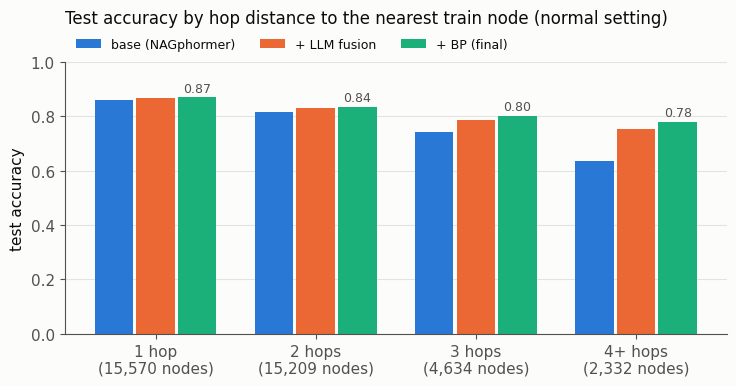

,base (NAGphormer),+ LLM fusion,+ BP (final)
1 hops,0.861,0.868,0.870
2 hops,0.816,0.830,0.835
3 hops,0.741,0.788,0.801
4+ hops,0.636,0.754,0.779


In [7]:
import matplotlib.pyplot as plt
import scipy.sparse as sp

INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # reference categorical slots 1-3 (validated all-pairs)
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

ei = graph.edge_index.numpy()
A = sp.csr_matrix((np.ones(ei.shape[1]), (ei[0], ei[1])), shape=(len(y), len(y)))
dist = np.full(len(y), np.inf); dist[tr] = 0; frontier, h = tr.copy(), 0
while frontier.any():
    h += 1
    frontier = ((A @ frontier.astype(float)) > 0) & np.isinf(dist)
    dist[frontier] = h
buckets = {"1": dist == 1, "2": dist == 2, "3": dist == 3, "4+": dist >= 4}
show = ["base (NAGphormer)", "+ LLM fusion", "+ BP (final)"]
acc = {s: [np.mean([(Z[(t, "normal", sd, s)][te & m] == y[te & m]).mean() for t in tags for sd in range(3)])
           for m in buckets.values()] for s in show}

fig, ax = plt.subplots(figsize=(7.5, 4))
x, w = np.arange(len(buckets)), 0.26
for i, s in enumerate(show):
    bars = ax.bar(x + (i - 1) * w, acc[s], w - 0.02, color=SERIES[i], label=s)
ax.bar_label(bars, fmt="%.2f", padding=2, color=MUTED, fontsize=9)  # direct labels on the final step only
ax.set_xticks(x, [f"{k} hop{'s' if k != '1' else ''}\n({(te & m).sum():,} nodes)" for k, m in buckets.items()])
ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.0)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=9)
ax.set_title("Test accuracy by hop distance to the nearest train node (normal setting)", loc="left", fontsize=12,
             pad=28)
plt.tight_layout(); plt.show()
pd.DataFrame(acc, index=[f"{k} hops" for k in buckets]).round(3)

### Recall on the classes that are rare in train but large in test

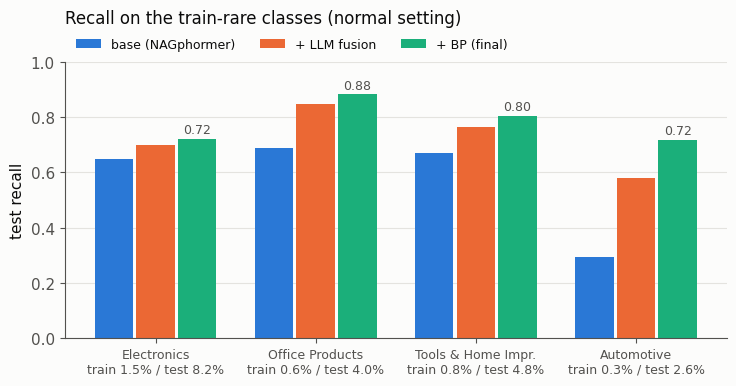

In [8]:
rare = {12: "Electronics", 18: "Office Products", 21: "Tools & Home Impr.", 16: "Automotive"}
rec = {s: [np.mean([(Z[(t, "normal", sd, s)][te & (y == c)] == c).mean() for t in tags for sd in range(3)])
           for c in rare] for s in show}
shares = [f"train {np.mean(y[tr] == c):.1%} / test {np.mean(y[te] == c):.1%}" for c in rare]
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(rare))
for i, s in enumerate(show):
    bars = ax.bar(x + (i - 1) * w, rec[s], w - 0.02, color=SERIES[i], label=s)
ax.bar_label(bars, fmt="%.2f", padding=2, color=MUTED, fontsize=9)
ax.set_xticks(x, [f"{n}\n{sh}" for n, sh in zip(rare.values(), shares)], fontsize=9)
ax.set_ylabel("test recall"); ax.set_ylim(0, 1.0)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=9)
ax.set_title("Recall on the train-rare classes (normal setting)", loc="left", fontsize=12, pad=28)
plt.tight_layout(); plt.show()

### What the remaining errors are

About 4% of test cannot be predicted from the labels we have: class 42 "Baby" has no train or val node, and class 24 "MISSING" is a missing-metadata class. Electronics -> Cell Phones is concept shift: tablet accessories are labelled Cell Phones in train (91% of 109) but Electronics in test (82% of 721). See `docs/method.md`, section "The remaining errors".

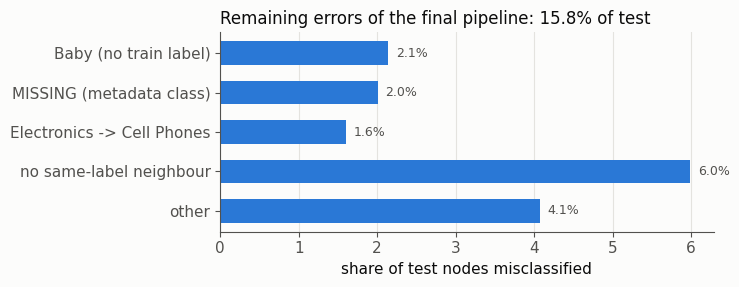

test accuracy without Baby and MISSING: 0.8783


In [9]:
r, c = ei
same = np.bincount(r, weights=(y[r] == y[c]), minlength=len(y)); deg = np.bincount(r, minlength=len(y))
het = (deg > 0) & (same == 0)
counts = []
for t in tags:
    for sd in range(3):
        pred = Z[(t, "normal", sd, "+ BP (final)")]; err = te & (pred != y); used = np.zeros(len(y), bool); row = {}
        for k, m in {"Baby (no train label)": y == 42, "MISSING (metadata class)": y == 24,
                     "Electronics -> Cell Phones": (y == 12) & (pred == 8), "no same-label neighbour": het,
                     "other": np.ones(len(y), bool)}.items():
            row[k] = (err & m & ~used).sum(); used |= err & m
        counts.append(row)
err = pd.DataFrame(counts).mean()
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh(err.index[::-1], (err / te.sum() * 100)[::-1], color=SERIES[0], height=0.6)
for i, v in enumerate((err / te.sum() * 100)[::-1]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", color=MUTED, fontsize=9)
ax.set_xlabel("share of test nodes misclassified"); ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title(f"Remaining errors of the final pipeline: {err.sum() / te.sum():.1%} of test", loc="left", fontsize=12)
plt.tight_layout(); plt.show()
ok = te & (y != 42) & (y != 24)
print("test accuracy without Baby and MISSING: %.4f" % np.mean(
    [(Z[(t, "normal", sd, "+ BP (final)")][ok] == y[ok]).mean() for t in tags for sd in range(3)]))